# NumCompute-Stream demo: a buffered decision tree on a drifting stream

**Assignment 2.2 · Programming Task 2 · `numcompute_stream`, built on the team's `numcompute` package**

This notebook walks through the whole pipeline:

1. **Load** a CSV with the package's I/O (`numcompute_stream.io`, which parses with `numcompute.io.load_csv`), no pandas.
2. **Stream** it in chunks and keep **running statistics** without storing old chunks.
3. **Train incrementally** with `partial_fit`: the tree buffers chunks and retrains when the buffer reaches `buffer_size`.
4. **Evaluate prequentially** (predict each chunk *before* training on it) and **log** metrics.
5. **Visualise** accuracy over time, retrains, the confusion matrix, and a comparison of models.

The dataset (`data/stream_data.csv`, made by `data/make_stream_data.py`) is a synthetic sensor stream: 6000 readings, 5 features, 3 classes (`normal`, `warning`, `fault`), about 3% missing values, and a **concept drift at row 3000** where the rule linking sensors to status changes.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# find the NumCompute folder whether the notebook runs from demo/ or from the project root
ROOT = next(p for base in (Path.cwd(), *Path.cwd().parents)
            for p in (base, base / "NumCompute") if (p / "numcompute_stream").is_dir())
sys.path.insert(0, str(ROOT))

from numcompute_stream import (ColumnStats, DecisionTree, DecisionTreeClassifier, NotFittedError,
                               StreamTrainer, StreamingImputer, StreamingMetrics,
                               StreamingOneHotEncoder, StreamingPipeline, iter_chunks,
                               load_labelled_csv, prequential_run)
from numcompute_stream import visualise as vis

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)
DATA = ROOT / "data" / "stream_data.csv"
CHUNK, DRIFT_AT = 200, 3000
print("data file:", DATA.relative_to(ROOT))

data file: data/stream_data.csv


## 1. Load the CSV

In [2]:
X, y, feature_names = load_labelled_csv(DATA, label_column="status")
print("X shape:", X.shape, "| y shape:", y.shape)
print("features:", feature_names)
print("missing values:", int(np.isnan(X).sum()), "of", X.size)
classes, counts = np.unique(y, return_counts=True)
print("class counts:", dict(zip(classes.tolist(), counts.tolist())))

X shape: (6000, 5) | y shape: (6000,)
features: ['temperature', 'vibration', 'pressure', 'load', 'noise']
missing values: 948 of 30000
class counts: {'fault': 1220, 'normal': 3476, 'warning': 1304}


## 2. Running statistics over the stream

`ColumnStats` folds in one chunk at a time (one `numcompute.stats.RunningStats` per feature, so Welford's update and the NaN skipping live in one place). After the last chunk it matches NumPy's full-data answer, but it only ever stored a count, a mean and a sum of squared deviations per feature.

In [3]:
stats = ColumnStats()
for X_chunk, _ in iter_chunks(X, y, CHUNK):
    stats.update(X_chunk)

print("chunks processed:", stats.n_chunks_)
for name, m, s, c in zip(feature_names, stats.mean, stats.std, stats.count_):
    print(f"{name:>12}: mean {m:9.3f}   std {s:8.3f}   non-missing {int(c)}")
print("matches np.nanmean:", np.allclose(stats.mean, np.nanmean(X, axis=0)))
print("matches np.nanvar: ", np.allclose(stats.var, np.nanvar(X, axis=0)))

chunks processed: 30
 temperature: mean    60.011   std   10.044   non-missing 5796
   vibration: mean     2.968   std    2.092   non-missing 5810
    pressure: mean   100.206   std   15.012   non-missing 5819
        load: mean     0.496   std    0.290   non-missing 5817
       noise: mean     0.010   std    0.992   non-missing 5810
matches np.nanmean: True
matches np.nanvar:  True


## 3. Train incrementally with `partial_fit`, evaluated prequentially

The pipeline is a `StreamingImputer` (fills NaN with the running mean) followed by the `DecisionTree`. With `buffer_size=500` and chunks of 200 rows, the tree retrains after every 3rd chunk (600 ≥ 500), then empties its buffer.

`prequential_run` predicts each chunk **before** training on it, so every score is on data the model has never seen. The log shows the chunks that only fill the first buffer, then one line per scored chunk.

In [4]:
pipe = StreamingPipeline([
    ("imputer", StreamingImputer()),
    ("tree", DecisionTree(max_depth=6, min_samples_leaf=5, buffer_size=500)),
])
metrics = prequential_run(pipe, iter_chunks(X, y, CHUNK))
tree = pipe.named_steps["tree"]
print(f"\nfinal prequential accuracy: {metrics.accuracy:.3f}   macro F1: {metrics.macro_f1:.3f}")
print(f"retrains: {tree.n_retrains_}, samples left in buffer: {tree.n_buffered_}")

INFO chunk   1 | buffering (200/500), no tree yet


INFO chunk   2 | buffering (400/500), no tree yet


INFO chunk   3 | first tree trained on 600 buffered rows (not scored)


INFO chunk   4 | rows_read=   800 | chunk_acc=0.715 | cum_acc=0.715 | retrains=1


INFO chunk   5 | rows_read=  1000 | chunk_acc=0.665 | cum_acc=0.690 | retrains=1


INFO chunk   6 | rows_read=  1200 | chunk_acc=0.720 | cum_acc=0.700 | retrains=2


... (21 outputs left out)

INFO chunk  28 | rows_read=  5600 | chunk_acc=0.815 | cum_acc=0.732 | retrains=9


INFO chunk  29 | rows_read=  5800 | chunk_acc=0.810 | cum_acc=0.735 | retrains=9


INFO chunk  30 | rows_read=  6000 | chunk_acc=0.745 | cum_acc=0.736 | retrains=10



final prequential accuracy: 0.736   macro F1: 0.674
retrains: 10, samples left in buffer: 0


### Retrain log: one entry per retrained tree

In [5]:
print(f"{'retrain':>7} {'samples':>8} {'ms':>7} {'depth':>6} {'leaves':>7} {'train acc':>10}")
for e in tree.retrain_log_:
    print(f"{e['retrain']:>7} {e['n_samples']:>8} {e['seconds'] * 1000:>7.2f} "
          f"{e['depth']:>6} {e['n_leaves']:>7} {e['train_accuracy']:>10.3f}")

retrain  samples      ms  depth  leaves  train acc
      1      600    5.91      6      40      0.875
      2      600    5.19      6      40      0.835
      3      600    5.34      6      42      0.868
      4      600    5.01      6      38      0.857
      5      600    5.02      6      38      0.850
      6      600    4.86      6      35      0.877
      7      600    5.43      6      41      0.893
      8      600    4.25      6      31      0.903
      9      600    4.49      6      33      0.912
     10      600    4.84      6      31      0.890


## 4. Visualise metrics over time

Dotted vertical lines mark retrains. The dip after row 3000 is the concept drift: the current tree was trained on the old rule. Accuracy recovers once the buffer fills with post-drift data and the tree retrains.

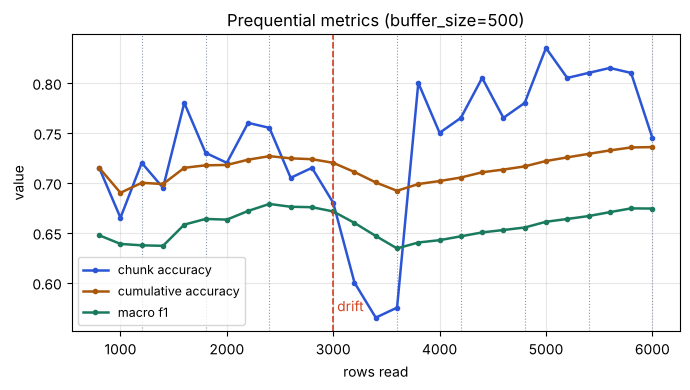

In [6]:
fig, ax = vis.plot_metric_history(metrics, keys=("chunk_accuracy", "cumulative_accuracy", "macro_f1"),
                                  x_key="rows_read", title="Prequential metrics (buffer_size=500)")
ax.axvline(DRIFT_AT, color="#cf4320", ls="--", lw=1.2)
ax.text(DRIFT_AT, ax.get_ylim()[0] + 0.02, " drift", color="#cf4320")
plt.show()

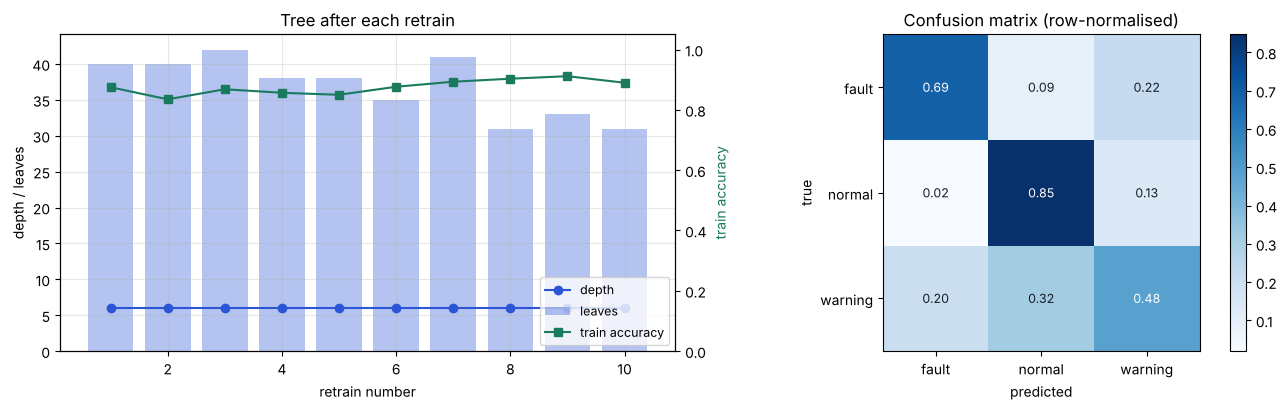

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
vis.plot_retrain_log(tree.retrain_log_, ax=axes[0])
vis.plot_confusion_matrix(metrics.confusion_, metrics.labels_, normalise=True, ax=axes[1],
                          title="Confusion matrix (row-normalised)")
plt.show()

## 5. Model comparison

Three ways to handle the same stream:

* **static**: trained once on the first 1000 rows, never updated (what you get with no streaming);
* **buffered, buffer_size=250** and **buffer_size=2000**: the same tree, retrained more or less often.

All three are scored on the same rows (from row 2000 on), so the curves are directly comparable.

    static (first 1000 rows): overall 0.650 | before drift 0.737 | after drift 0.622
   buffered, buffer_size=250: overall 0.732 | before drift 0.720 | after drift 0.736
  buffered, buffer_size=2000: overall 0.713 | before drift 0.750 | after drift 0.700


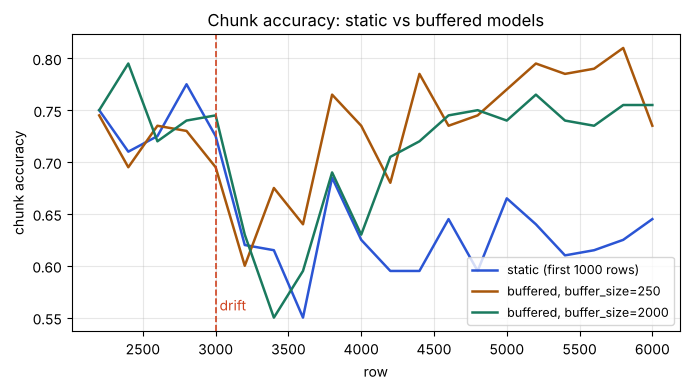

In [8]:
def run_static(train_rows=1000, score_from=2000):
    imputer = StreamingImputer().fit(X[:train_rows])
    model = DecisionTree(max_depth=6, min_samples_leaf=5).fit(imputer.transform(X[:train_rows]),
                                                              y[:train_rows])
    scores = StreamingMetrics()
    for start in range(score_from, len(y), CHUNK):
        X_chunk, y_chunk = X[start:start + CHUNK], y[start:start + CHUNK]
        scores.update(y_chunk, model.predict(imputer.transform(X_chunk)), row=start + CHUNK)
    return scores

def run_buffered(buffer_size, score_from=2000):
    p = StreamingPipeline([("imputer", StreamingImputer()),
                           ("tree", DecisionTree(max_depth=6, min_samples_leaf=5,
                                                 buffer_size=buffer_size))])
    scores = StreamingMetrics()
    for i, (X_chunk, y_chunk) in enumerate(iter_chunks(X, y, CHUNK)):
        start = i * CHUNK
        if start >= score_from:
            scores.update(y_chunk, p.predict(X_chunk), row=start + CHUNK)   # test ...
        p.partial_fit(X_chunk, y_chunk)                                      # ... then train
    return scores

runs = {"static (first 1000 rows)": run_static(),
        "buffered, buffer_size=250": run_buffered(250),
        "buffered, buffer_size=2000": run_buffered(2000)}
for name, scores in runs.items():
    acc, rows = scores.series("chunk_accuracy"), scores.series("row")
    print(f"{name:>28}: overall {scores.accuracy:.3f} | before drift {acc[rows <= DRIFT_AT].mean():.3f} "
          f"| after drift {acc[rows > DRIFT_AT].mean():.3f}")

fig, ax = vis.plot_model_comparison(runs, key="chunk_accuracy", x_key="row",
                                    title="Chunk accuracy: static vs buffered models")
ax.axvline(DRIFT_AT, color="#cf4320", ls="--", lw=1.2)
ax.text(DRIFT_AT, ax.get_ylim()[0] + 0.02, " drift", color="#cf4320")
plt.show()

## 6. `StreamTrainer` and the three plots from the brief

`StreamTrainer` is the loop from section 3 packaged as a class. `score_chunk` tests on a chunk first (it returns `None` until a tree exists), `fit_chunk` then trains on it and logs the time, the memory the tree holds and the cumulative accuracy. `run` does both for every chunk.

It takes the brief's `DecisionTreeClassifier` (an alias of `DecisionTree`). The tree fills NaN itself, so no imputer is needed here.

In [9]:
def make_trainer(buffer_size):
    model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, buffer_size=buffer_size)
    return StreamTrainer(model, log_every=0).run(iter_chunks(X, y, CHUNK))

trainer = make_trainer(500)
print(f"chunks: {trainer.n_chunks_}   cumulative accuracy: {trainer.cumulative_accuracy:.3f}\n")
print(f"{'chunk':>5} {'fit ms':>8} {'tree bytes':>11} {'retrains':>9} {'cum. acc':>9}")
for e in trainer.log_[::5]:                                  # every 5th chunk
    print(f"{e['chunk']:>5} {e['seconds'] * 1000:>8.2f} {e['memory_bytes']:>11} "
          f"{e['retrains']:>9} {e['cumulative_accuracy']:>9.3f}")

chunks: 30   cumulative accuracy: 0.736

chunk   fit ms  tree bytes  retrains  cum. acc
    1     0.37       13600         0       nan
    6     5.48        1896         2     0.700
   11     0.03       29336         3     0.718
   16     0.05       15400         5     0.712
   21     5.44        1944         7     0.707
   26     0.03       28616         8     0.726


### `plot_metric_over_time`

One metric, one value per scored chunk. The first chunks are not scored because no tree exists yet.

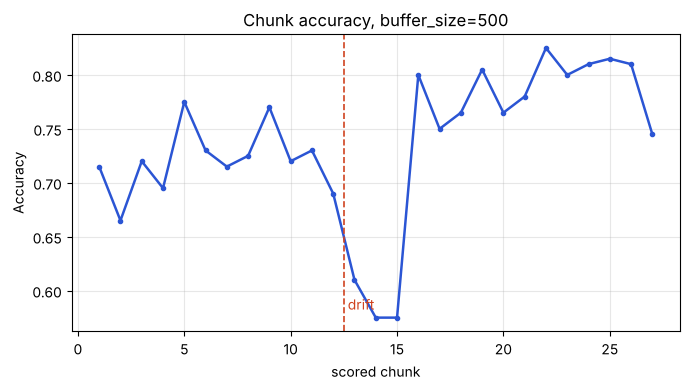

In [10]:
acc_500 = trainer.metrics.series("chunk_accuracy")
fig, ax = vis.plot_metric_over_time(acc_500, title="Chunk accuracy, buffer_size=500",
                                    ylabel="Accuracy", xlabel="scored chunk")
first_scored = -(-500 // CHUNK)                        # chunks that only fill the first buffer
drift_x = DRIFT_AT / CHUNK - first_scored + 0.5       # boundary between two scored chunks
ax.axvline(drift_x, color="#cf4320", ls="--", lw=1.2)
ax.text(drift_x, ax.get_ylim()[0] + 0.02, " drift", color="#cf4320")
plt.show()

### `compare_models`

Two accuracy series on one axis. The curves have different lengths because a bigger buffer waits longer for its first tree, so the x axis counts scored chunks, not rows.

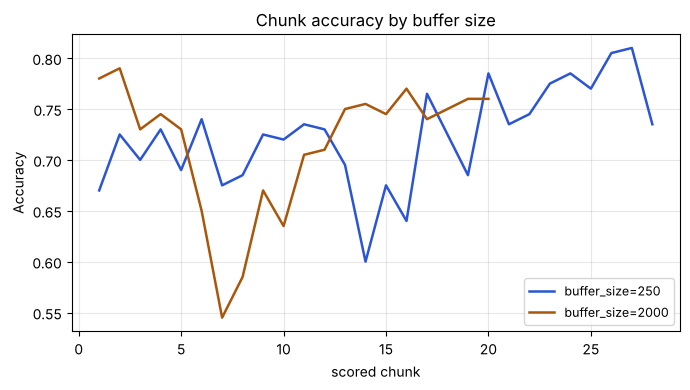

In [11]:
acc_250 = make_trainer(250).metrics.series("chunk_accuracy")
acc_2000 = make_trainer(2000).metrics.series("chunk_accuracy")
fig, ax = vis.compare_models(acc_250, acc_2000, labels=("buffer_size=250", "buffer_size=2000"),
                             title="Chunk accuracy by buffer size", xlabel="scored chunk")
plt.show()

### `plot_predictions_vs_ground_truth`

Every row of one chunk: a hollow circle is the true class, a filled dot the prediction, and a red cross marks a mistake. Here the last 40 rows of the stream are predicted by the tree as it stands at the end.

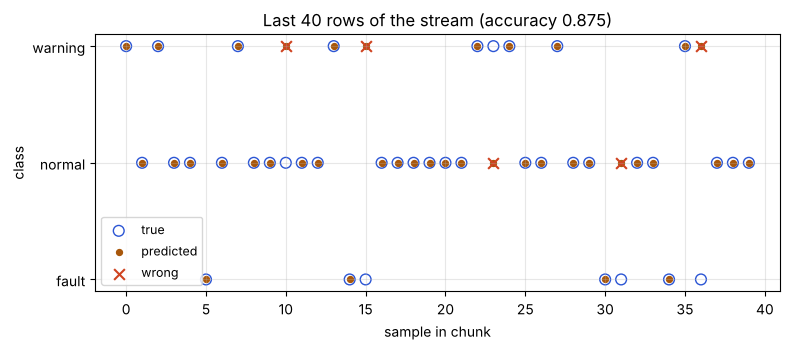

correct: 35 of 40


In [12]:
last_X, last_y = X[-40:], y[-40:]
last_pred = trainer.model.predict(last_X)
fig, ax = vis.plot_predictions_vs_ground_truth(last_y, last_pred, title="Last 40 rows of the stream")
plt.show()
print("correct:", int((last_y == last_pred).sum()), "of", len(last_y))

## 7. Predictions from the current tree

In [13]:
X_new = np.array([[55.0, 1.2, 98.0, 0.20, 0.0],     # cool, calm, light load
                  [70.0, 6.5, 110.0, 0.90, 0.0],    # hot, high vibration, heavy load
                  [np.nan, 3.0, 100.0, 0.50, 0.0]]) # missing temperature
print("predictions:", pipe.predict(X_new))
print("classes:    ", tree.classes_)
print("probabilities:\n", np.round(pipe.predict_proba(X_new), 3))
print("\nfeature importances:")
for name, w in sorted(zip(feature_names, tree.feature_importances_), key=lambda t: -t[1]):
    print(f"  {name:>12}: {w:.3f}")

predictions: ['normal' 'fault' 'warning']
classes:     ['normal' 'warning' 'fault']
probabilities:
 [[0.991 0.009 0.   ]
 [0.    0.    1.   ]
 [0.158 0.737 0.105]]

feature importances:
     vibration: 0.701
   temperature: 0.166
          load: 0.084
      pressure: 0.034
         noise: 0.015


In [14]:
print(tree.export_text(feature_names, decimals=2)[:1500], "\n...")

|--- vibration <= 3.85
|   |--- vibration <= 2.82
|   |   |--- load <= 0.88
|   |   |   |--- temperature <= 75.16
|   |   |   |   |--- noise <= 1.69
|   |   |   |   |   |--- vibration <= 2.55
|   |   |   |   |   |   |--- class: normal  (n=214)
|   |   |   |   |   |--- vibration >  2.55
|   |   |   |   |   |   |--- class: normal  (n=24)
|   |   |   |   |--- noise >  1.69
|   |   |   |   |   |--- temperature <= 59.69
|   |   |   |   |   |   |--- class: normal  (n=10)
|   |   |   |   |   |--- temperature >  59.69
|   |   |   |   |   |   |--- class: warning  (n=5)
|   |   |   |--- temperature >  75.16
|   |   |   |   |--- vibration <= 1.88
|   |   |   |   |   |--- temperature <= 77.44
|   |   |   |   |   |   |--- class: normal  (n=5)
|   |   |   |   |   |--- temperature >  77.44
|   |   |   |   |   |   |--- class: normal  (n=5)
|   |   |   |   |--- vibration >  1.88
|   |   |   |   |   |--- class: warning  (n=7)
|   |   |--- load >  0.88
|   |   |   |--- vibration <= 1.58
|   |   |   |   |

## 8. Incremental one-hot encoding

`StreamingOneHotEncoder` learns its categories chunk by chunk. When a new category shows up in a later chunk the output gets another column. A category it has never seen is rejected at `transform` time rather than silently dropped.

In [15]:
enc = StreamingOneHotEncoder()
enc.partial_fit(np.array([[1.0], [2.0], [1.0]]))
print("after chunk 1, categories:", enc.categories_[0])
print(enc.transform(np.array([[2.0], [1.0]])))

enc.partial_fit(np.array([[3.0], [2.0]]))            # a new category arrives in chunk 2
print("\nafter chunk 2, categories:", enc.categories_[0])
print(enc.transform(np.array([[3.0], [1.0]])))

try:
    enc.transform(np.array([[9.0]]))
except ValueError as err:
    print("\nunseen category ->", err)

after chunk 1, categories: [1. 2.]
[[0. 1.]
 [1. 0.]]

after chunk 2, categories: [1. 2. 3.]
[[0. 0. 1.]
 [1. 0. 0.]]

unseen category -> Found unknown categories during transform


## 9. Edge cases under streaming

The framework is built to fail loudly and helpfully, or to degrade gracefully.

In [16]:
fresh = DecisionTree(buffer_size=500)
fresh.partial_fit(X[:200], y[:200])
try:
    fresh.predict(X[:3])
except NotFittedError as err:
    print("predict before first retrain ->", err)

fresh.partial_fit(np.empty((0, 5)), np.array([]))
print("empty chunk -> ignored, buffer still", fresh.n_buffered_)

try:
    fresh.partial_fit(X[:10, :3], y[:10])
except ValueError as err:
    print("wrong number of features ->", err)

try:
    fresh.partial_fit(X[0], y[:1])
except ValueError as err:
    print("1-D input ->", err)

const = DecisionTree(buffer_size=50).partial_fit(np.full((50, 5), 1.0), y[:50])
print("zero-variance chunk -> single leaf, n_leaves =", const.get_n_leaves())

fresh.flush()
print("flush() at end of stream -> retrains on the leftover buffer; retrains =", fresh.n_retrains_)

predict before first retrain -> fit must be called before predict. No tree has been trained yet: the buffer holds 200/500 samples. Send more data with partial_fit() or call flush().
empty chunk -> ignored, buffer still 200
wrong number of features -> Incompatible dimensionality. X has 3 feature(s), but this object was fitted with 5.
1-D input -> Input data must have 2 dimensions. Got shape: (5,)
zero-variance chunk -> single leaf, n_leaves = 1
flush() at end of stream -> retrains on the leftover buffer; retrains = 1


## Summary

* The tree trains only through `partial_fit` and retrains whenever the buffer reaches `buffer_size`.
* Prequential accuracy is honest: every chunk is scored before the model trains on it.
* Under concept drift a static model stays wrong, while the buffered tree recovers after its next retrain or two; a smaller buffer recovers sooner but trains each tree on less data.
* `StreamTrainer` wraps the same test-then-train loop and logs time, memory and accuracy per chunk.
* `StreamingOneHotEncoder` adds columns when a new category arrives, so categorical features can stream too.
* See `benchmark/` for the loop-vs-vectorised timings and the full `buffer_size` sweep.